# 07 · Is take-off a shortcut?

Take-off is classified almost perfectly by every probe so far (24/24 on the session-aware test set). That can be legitimate (the pose of a take-off is distinctive) or a shortcut (take-off clips may come from different scenes, such as wave pools or other camera setups, so the model could recognize the place instead of the maneuver).

Three checks with the data already available:
1. how take-off clips are distributed across session groups and sources;
2. a visual look at take-off scenes next to other maneuvers;
3. an appearance-only probe (DINOv2 on 3 still frames, no motion) against the motion probe (V-JEPA 2), per class.

## 1. Setup and data

In [1]:
import sys
from pathlib import Path

# Make the project root importable (notebooks/ is one level below it)
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src.data.features import load_features
from src.data.inventory import build_clip_table
from src.data.splits import random_group_folds
from src.data.video import read_frame

splits = pd.read_csv(PROJECT_ROOT / "data" / "splits.csv")

# Clip table in the same order as the DINOv2 cache from notebook 02, keyed like splits.csv
table = build_clip_table()
table["clip"] = table["split"] + "/" + table["maneuver"] + "/" + table["file"]
dino = np.load(PROJECT_ROOT / "data" / "processed" / "dinov2_small_frame_embeddings.npz", allow_pickle=True)
assert list(dino["files"]) == table["file"].tolist(), "DINOv2 cache does not match the clip table"
dino_by_clip = dict(zip(table["clip"], dino["embeddings"]))

# Bring each clip's source and video path into the split table
splits = splits.merge(table[["clip", "source", "path"]], on="clip", how="left")

X_motion = load_features(splits).mean(axis=1)                          # V-JEPA 2, (1056, 1024)
X_appearance = np.stack([dino_by_clip[c] for c in splits["clip"]])     # DINOv2 still frames, (1056, 384)
y = splits["maneuver"].to_numpy()
groups = splits["group"].to_numpy()
classes = sorted(splits["maneuver"].unique())

print("motion", X_motion.shape, "| appearance", X_appearance.shape)

motion (1056, 1024) | appearance (1056, 384)


## 2. Where take-off clips come from

In [2]:
# Clips of each class inside every session group
per_group = pd.crosstab(splits["group"], splits["maneuver"])
takeoff_groups = per_group[per_group["take-off"] > 0].copy()
# Share of take-off among the clips of each group that contains take-off
takeoff_groups["takeoff_share"] = (takeoff_groups["take-off"] / per_group.loc[takeoff_groups.index].sum(axis=1)).round(2)

print(f"{per_group['take-off'].sum()} take-off clips in {len(takeoff_groups)} of {len(per_group)} session groups\n")
print(takeoff_groups.sort_values("take-off", ascending=False), "\n")

# Same question by naming source (a proxy for where the clip was exported from)
print(pd.crosstab(splits["source"], splits["maneuver"]))

121 take-off clips in 28 of 36 session groups

maneuver  360  cutback-frontside  roller  take-off  takeoff_share
group                                                            
10          7                  4       4        10           0.40
31          0                  0       6        10           0.62
28          1                  4      12        10           0.37
1           3                 13      29         9           0.17
5           7                  1      14         8           0.27
20          2                  6      14         8           0.27
13          4                  0      28         6           0.16
32          4                  4      16         6           0.20
6          50                 24      50         6           0.05
2           5                  2       7         5           0.26
23          7                  8       5         5           0.20
14          7                 18      24         5           0.09
18          7                

## 3. A look at the scenes

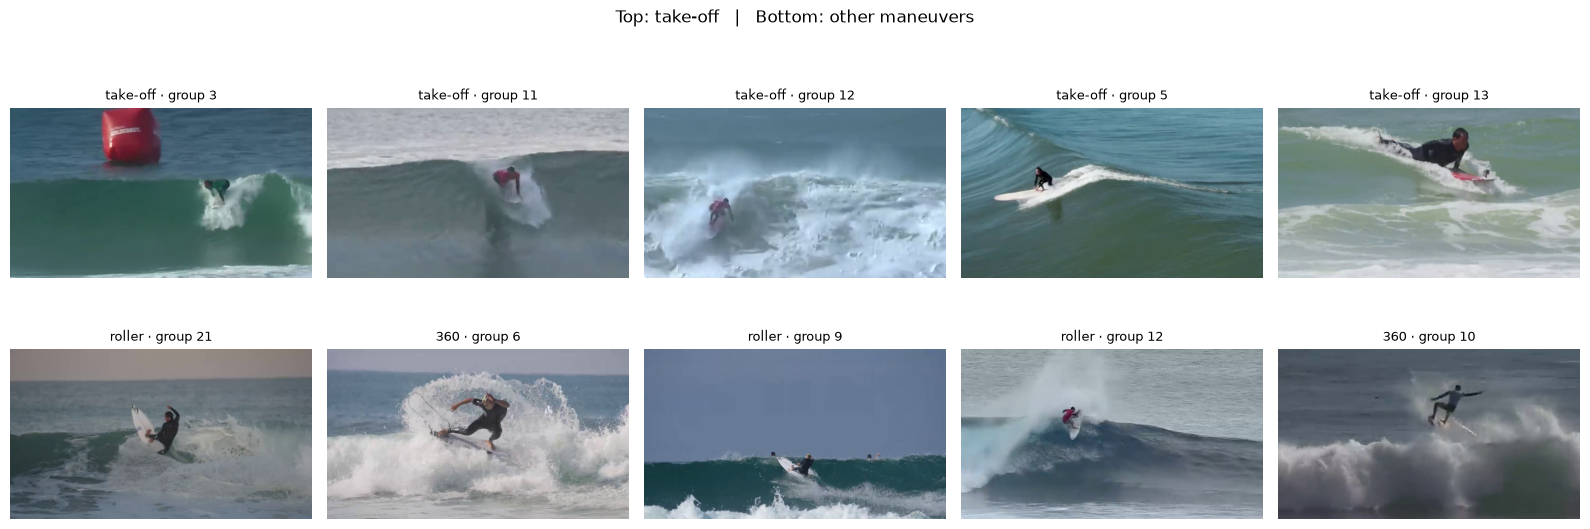

In [3]:
# Middle frame of 5 random take-offs (top) and 5 random other clips (bottom). Notebook only: dataset frames are not reused elsewhere.
samples = {
    "take-off": splits[splits["maneuver"] == "take-off"].sample(5, random_state=0),
    "other maneuvers": splits[splits["maneuver"] != "take-off"].sample(5, random_state=0),
}
fig, axes = plt.subplots(2, 5, figsize=(16, 6), squeeze=False)
for row, (label, sample) in enumerate(samples.items()):
    for col, (_, clip) in enumerate(sample.iterrows()):
        ax = axes[row, col]
        ax.imshow(read_frame(clip["path"], 0.5))
        ax.set_title(f"{clip['maneuver']} · group {clip['group']}", fontsize=9)
        ax.axis("off")
fig.suptitle("Top: take-off   |   Bottom: other maneuvers", fontsize=12)
plt.tight_layout()
plt.show()

## 4. Appearance-only vs motion features

In [4]:
N_REPEATS, N_FOLDS = 10, 5

def per_class_f1(X):
    """Per-class F1 of the linear probe, one row per repeat of session-aware 5-fold CV.

    Predictions of the 5 folds are pooled (each clip predicted once per repeat) before scoring,
    so a class that is absent from one fold does not distort the result.
    """
    rows = []
    for repeat in range(N_REPEATS):
        pred = np.empty_like(y)
        for train_idx, test_idx in random_group_folds(y, groups, N_FOLDS, seed=repeat):
            probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, class_weight="balanced"))
            probe.fit(X[train_idx], y[train_idx])
            pred[test_idx] = probe.predict(X[test_idx])
        rows.append(f1_score(y, pred, labels=classes, average=None))
    return pd.DataFrame(rows, columns=classes)

f1_by_features = {
    "appearance (DINOv2, still frames)": per_class_f1(X_appearance),
    "motion (V-JEPA 2)": per_class_f1(X_motion),
}

# Mean ± std over repeats, with macro F1 as the average of the classes
summary = {}
for name, scores in f1_by_features.items():
    scores = scores.assign(macro=scores.mean(axis=1))
    summary[name] = scores.mean().round(3).astype(str) + " ± " + scores.std().round(3).astype(str)
pd.DataFrame(summary)

,"appearance (DINOv2, still frames)",motion (V-JEPA 2)
360,0.673 ± 0.017,0.851 ± 0.017
cutback-frontside,0.683 ± 0.013,0.836 ± 0.01
roller,0.77 ± 0.008,0.891 ± 0.007
take-off,0.899 ± 0.013,0.944 ± 0.014
macro,0.756 ± 0.007,0.88 ± 0.007


## 5. Findings

- **No sign of a scene shortcut for take-off.** The 121 take-off clips are spread over 28 of the 36 session groups and always share them with other maneuvers (take-off share per group between 0.05 and 0.62). Both naming sources contain take-off. The sampled frames show the same open-ocean contest footage for take-off and the other classes; there are no wave-pool scenes.
- **Take-off is recognizable from still frames, most likely by pose.** With an appearance-only probe (DINOv2, 3 still frames) take-off keeps F1 0.899, only 4.5 points below the motion features (V-JEPA 2, 0.944). The other classes lose 12 to 18 points without motion (360: 0.851 → 0.673, cutback: 0.836 → 0.683, roller: 0.891 → 0.770). Since scenes are shared across classes, the paddling and pop-up posture is the most plausible cue.
- **Motion features matter for the other maneuvers.** Macro F1 rises from 0.756 (appearance) to 0.880 (motion) under the same 50 session-aware folds. This comparison also changes the encoder size (DINOv2-small, 384-d, vs V-JEPA 2 ViT-L, 1024-d), so it is not a pure appearance-vs-motion ablation.
- **The perfect take-off score of notebook 04 (24/24) was split luck.** Over 50 session-aware folds, take-off F1 is 0.944 ± 0.014.
- **A possible source confound for roller.** The `roller` naming source (files named Roller_XX) holds 45 clips, all labeled roller. If those files differ in export style, the model could use that as a cue. To be checked.
- **Next.** With surfer detection: classify the surfer crop (pose only) and the frame with the surfer masked out (scene only), to separate pose from scene cues directly.